### Group 5: Does Donald Trump Have Dementia?
A NLP-analysis of "Donald Trump Rev.com Speech Transcripts Dataset", a dataset containing over 500 Donald Trump Speeches from the years of 2015-2024. 

In [1]:
#import all the things

import json
from pathlib import Path
import pandas as pd
import matplotlib.pylab as plt
import seaborn as sns


## Dataset

In [2]:
#load dataset

data_dir = Path.cwd() / 'data'
file_path = data_dir / 'Obama_Speeches.json'

if not file_path.is_file():
    raise FileNotFoundError(
        f'Missing dataset: {file_path}. See the README for setup instructions.')

with file_path.open('r', encoding='utf-8') as file:
    data = json.load(file)


#convert to csv    

df = pd.DataFrame(data)
df.to_csv(data_dir / 'ObamaSpeeches.csv', index=False, encoding='utf-8')

In [3]:
#preview original dataset

df.head(5)

,transcript,title,date,link,type,audience,topics,location
0,My fellow citizens: I stand here today humbled...,President Barack Obama's Inaugural Address,2009-01-21,https://obamawhitehouse.archives.gov/the-press...,address,general,political; representation,United States
1,"Hello, everybody. Please be seated. Still gett...",Remarks of the President in Welcoming Senior S...,2009-01-21,https://obamawhitehouse.archives.gov/the-press...,remarks,general,political; representation,United States
2,THE PRESIDENT: For the senior staff.\n\n\n\nTH...,Remarks of the President in Welcoming Senior S...,2009-01-21,https://obamawhitehouse.archives.gov/the-press...,remarks,general,political; representation,United States
3,"Well, it is great to see you. We are here toge...",Remarks by the President Before the Bipartisan...,2009-01-23,https://obamawhitehouse.archives.gov/the-press...,statement,general,political,United States
4,We begin this year and this Administration in ...,WEEKLY ADDRESS: President Barack Obama Discuss...,2009-01-24,https://obamawhitehouse.archives.gov/the-press...,address,general,political,United States


avg_word_len = average length of words in characters. higher value means he used longer words.

stop_word_rate = stop_word_count / word_count, gives what percentage of the speech are stop words.

non_stopwords = the speech without stopwords

lemmatized = the words of speech transformed into their stem forms

polarity = sentiment-analysis value, negative towards –1, neutral closer to 0, positive closer to +1.

subjectivity = value between 0 to 1 regarding how subjective the speech is, 0 more objective, 1 more subjective.

In [4]:
#sort original dataset by date

df['date'] = pd.to_datetime(df['date'])
df = (df.sort_values('date').reset_index(drop=True))

df.head(5)

,transcript,title,date,link,type,audience,topics,location
0,My fellow citizens: I stand here today humbled...,President Barack Obama's Inaugural Address,2009-01-21,https://obamawhitehouse.archives.gov/the-press...,address,general,political; representation,United States
1,"Hello, everybody. Please be seated. Still gett...",Remarks of the President in Welcoming Senior S...,2009-01-21,https://obamawhitehouse.archives.gov/the-press...,remarks,general,political; representation,United States
2,THE PRESIDENT: For the senior staff.\n\n\n\nTH...,Remarks of the President in Welcoming Senior S...,2009-01-21,https://obamawhitehouse.archives.gov/the-press...,remarks,general,political; representation,United States
3,"Well, it is great to see you. We are here toge...",Remarks by the President Before the Bipartisan...,2009-01-23,https://obamawhitehouse.archives.gov/the-press...,statement,general,political,United States
4,We begin this year and this Administration in ...,WEEKLY ADDRESS: President Barack Obama Discuss...,2009-01-24,https://obamawhitehouse.archives.gov/the-press...,address,general,political,United States


In [ ]:
#only the original transcript, title and date

obama_speeches = df[['transcript', 'title', 'date']].copy()
obama_speeches.head()

,transcript,title,date
0,My fellow citizens: I stand here today humbled...,President Barack Obama's Inaugural Address,2009-01-21
1,"Hello, everybody. Please be seated. Still gett...",Remarks of the President in Welcoming Senior S...,2009-01-21
2,THE PRESIDENT: For the senior staff.\n\n\n\nTH...,Remarks of the President in Welcoming Senior S...,2009-01-21
3,"Well, it is great to see you. We are here toge...",Remarks by the President Before the Bipartisan...,2009-01-23
4,We begin this year and this Administration in ...,WEEKLY ADDRESS: President Barack Obama Discuss...,2009-01-24


In [ ]:
#sort the entries after date

obama_speeches['date'] = pd.to_datetime(obama_speeches['date'])
obama_speeches = (obama_speeches.sort_values('date').reset_index(drop=True))


#change the order of the columns

obama_speeches = obama_speeches[['date', 'title', 'transcript']]

In [ ]:
#preview after sorting

obama_speeches.head()

,date,title,transcript
0,2009-01-21,President Barack Obama's Inaugural Address,My fellow citizens: I stand here today humbled...
1,2009-01-21,Remarks of the President in Welcoming Senior S...,"Hello, everybody. Please be seated. Still gett..."
2,2009-01-21,Remarks of the President in Welcoming Senior S...,THE PRESIDENT: For the senior staff.\n\n\n\nTH...
3,2009-01-23,Remarks by the President Before the Bipartisan...,"Well, it is great to see you. We are here toge..."
4,2009-01-24,WEEKLY ADDRESS: President Barack Obama Discuss...,We begin this year and this Administration in ...


## NLP Preprocessing

In [8]:
#import all the things

import nltk
nltk.download('punkt_tab') # Tokenizer
nltk.download('vader_lexicon') # Sentiment analysis
nltk.download('stopwords') # Stopwords
import gensim.downloader as api
from gensim import corpora
from gensim.models import LdaModel
from gensim.utils import simple_preprocess
wv = api.load("glove-wiki-gigaword-50")

[nltk_data] Downloading package punkt_tab to
[nltk_data]     /Users/alexandrafrick/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!
[nltk_data] Downloading package vader_lexicon to
[nltk_data]     /Users/alexandrafrick/nltk_data...
[nltk_data]   Package vader_lexicon is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     /Users/alexandrafrick/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [ ]:
#tokenize

from nltk.tokenize import word_tokenize, sent_tokenize

sentences_0 = sent_tokenize(obama_speeches["transcript"].iloc[0])
words_0 = word_tokenize(obama_speeches["transcript"].iloc[0])

print(sentences_0)
print(words_0)

["My fellow citizens: I stand here today humbled by the task before us, grateful for the trust you've bestowed, mindful of the sacrifices borne by our ancestors.", 'I thank President Bush for his service to our nation -- (applause) -- as well as the generosity and cooperation he has shown throughout this transition.', 'Forty-four Americans have now taken the presidential oath.', 'The words have been spoken during rising tides of prosperity and the still waters of peace.', 'Yet, every so often, the oath is taken amidst gathering clouds and raging storms.', 'At these moments, America has carried on not simply because of the skill or vision of those in high office, but because we, the people, have remained faithful to the ideals of our forebears and true to our founding documents.', 'So it has been; so it must be with this generation of Americans.', 'That we are in the midst of crisis is now well understood.', 'Our nation is at war against a far-reaching network of violence and hatred.', 

In [10]:
#stopwords, removing stopwords and punctuation

from nltk.corpus import stopwords
stop_words = stopwords.words('english')
print(stop_words[:10])

preproc_sentences = []
for sentence in sentences_0: 
    sentence = simple_preprocess(sentence)
    sentence = [w for w in sentence if w.lower() not in stop_words] 
    preproc_sentences.append(sentence)
        
print(preproc_sentences)

['a', 'about', 'above', 'after', 'again', 'against', 'ain', 'all', 'am', 'an']
[['fellow', 'citizens', 'stand', 'today', 'humbled', 'task', 'us', 'grateful', 'trust', 'bestowed', 'mindful', 'sacrifices', 'borne', 'ancestors'], ['thank', 'president', 'bush', 'service', 'nation', 'applause', 'well', 'generosity', 'cooperation', 'shown', 'throughout', 'transition'], ['forty', 'four', 'americans', 'taken', 'presidential', 'oath'], ['words', 'spoken', 'rising', 'tides', 'prosperity', 'still', 'waters', 'peace'], ['yet', 'every', 'often', 'oath', 'taken', 'amidst', 'gathering', 'clouds', 'raging', 'storms'], ['moments', 'america', 'carried', 'simply', 'skill', 'vision', 'high', 'office', 'people', 'remained', 'faithful', 'ideals', 'forebears', 'true', 'founding', 'documents'], ['must', 'generation', 'americans'], ['midst', 'crisis', 'well', 'understood'], ['nation', 'war', 'far', 'reaching', 'network', 'violence', 'hatred'], ['economy', 'badly', 'weakened', 'consequence', 'greed', 'part', 'a

In [11]:
#ignoring to lemmatize for now, want to keep the speeches intact

## Sentiment analysis

In [12]:
from nltk.sentiment.vader import SentimentIntensityAnalyzer

sia = SentimentIntensityAnalyzer()

first_speech = df['transcript'].iloc[0]
print(sia.polarity_scores(first_speech))

{'neg': 0.106, 'neu': 0.709, 'pos': 0.185, 'compound': 0.9997}


In [13]:
first_speech = df["transcript"].iloc[0]
sentences = sent_tokenize(first_speech)

sia = SentimentIntensityAnalyzer()
sentiments = [sia.polarity_scores(sentence) for sentence in sentences]

print(sentences[:2])
print(sentiments[:2])


["My fellow citizens: I stand here today humbled by the task before us, grateful for the trust you've bestowed, mindful of the sacrifices borne by our ancestors.", 'I thank President Bush for his service to our nation -- (applause) -- as well as the generosity and cooperation he has shown throughout this transition.']
[{'neg': 0.0, 'neu': 0.792, 'pos': 0.208, 'compound': 0.743}, {'neg': 0.0, 'neu': 0.736, 'pos': 0.264, 'compound': 0.7845}]


In [14]:
import numpy as np
sentiment_scores = [s['compound'] for s in sentiments]
# Which sentence were the most positive and negative?
print('Most positive: ' + sentences[np.argmax(sentiment_scores)])
print('Most negative: ' + sentences[np.argmin(sentiment_scores)])

Most positive: But those values upon which our success depends -- honesty and hard work, courage and fair play, tolerance and curiosity, loyalty and patriotism -- these things are old.
Most negative: Our nation is at war against a far-reaching network of violence and hatred.


Text(0.5, 0, 'Speech Index')

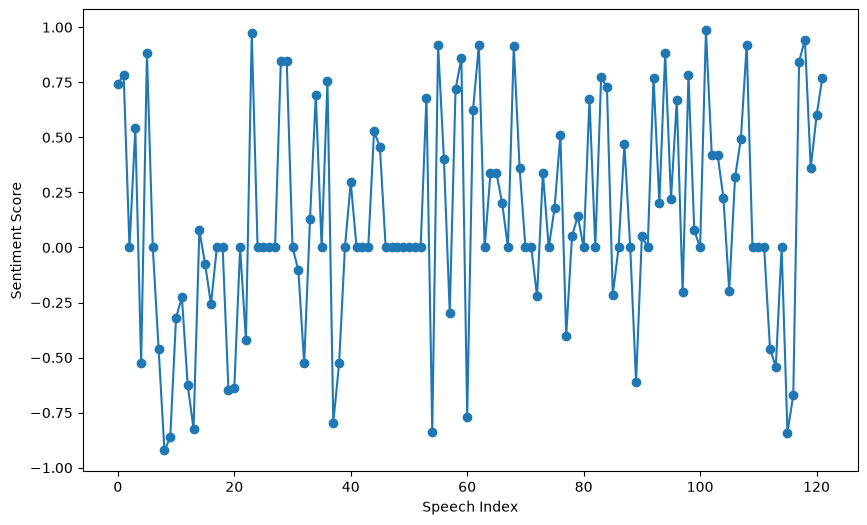

In [15]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(1, figsize=(10, 6))
ax.plot(sentiment_scores, marker='o')
ax.set_ylabel('Sentiment Score')
ax.set_xlabel('Speech Index')

## Topic Modelling

In [16]:
from gensim import corpora
from gensim.models import LdaModel
from gensim.utils import simple_preprocess
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer
from nltk.tokenize import word_tokenize, sent_tokenize
import numpy as np
import pandas as pd

In [17]:
lemmatizer = WordNetLemmatizer()
stop_words = stopwords.words('english') 
sentences = sent_tokenize(df['transcript'].iloc[0])
preproc_sentence = []
for sentence in sentences:
    sentence = simple_preprocess(sentence)
    sentence = [lemmatizer.lemmatize(w.lower()) for w in sentence if w.lower() not in stop_words]
    preproc_sentence.append(sentence)
print(preproc_sentence)

[['fellow', 'citizen', 'stand', 'today', 'humbled', 'task', 'u', 'grateful', 'trust', 'bestowed', 'mindful', 'sacrifice', 'borne', 'ancestor'], ['thank', 'president', 'bush', 'service', 'nation', 'applause', 'well', 'generosity', 'cooperation', 'shown', 'throughout', 'transition'], ['forty', 'four', 'american', 'taken', 'presidential', 'oath'], ['word', 'spoken', 'rising', 'tide', 'prosperity', 'still', 'water', 'peace'], ['yet', 'every', 'often', 'oath', 'taken', 'amidst', 'gathering', 'cloud', 'raging', 'storm'], ['moment', 'america', 'carried', 'simply', 'skill', 'vision', 'high', 'office', 'people', 'remained', 'faithful', 'ideal', 'forebear', 'true', 'founding', 'document'], ['must', 'generation', 'american'], ['midst', 'crisis', 'well', 'understood'], ['nation', 'war', 'far', 'reaching', 'network', 'violence', 'hatred'], ['economy', 'badly', 'weakened', 'consequence', 'greed', 'part', 'also', 'collective', 'failure', 'make', 'hard', 'choice', 'prepare', 'nation', 'new', 'age'], [

In [ ]:
dictionary = corpora.Dictionary(preproc_sentence)
# Make counts of each word
corpus = [dictionary.doc2bow(t) for t in preproc_sentence]
lda = LdaModel(corpus, num_topics=10, id2word=dictionary, random_state=42)

In [19]:
# Show topics
# Print the top words for each topic
for idx, topic in lda.print_topics():
    print(f"Topic {idx}: {topic}")

Topic 0: 0.019*"nation" + 0.015*"far" + 0.015*"greatness" + 0.010*"friend" + 0.009*"work" + 0.008*"u" + 0.008*"hour" + 0.008*"humble" + 0.008*"unfolds" + 0.008*"brave"
Topic 1: 0.017*"many" + 0.016*"work" + 0.015*"today" + 0.012*"whether" + 0.011*"u" + 0.011*"thing" + 0.011*"journey" + 0.010*"big" + 0.010*"question" + 0.010*"care"
Topic 2: 0.015*"time" + 0.013*"world" + 0.012*"nation" + 0.010*"oath" + 0.010*"taken" + 0.009*"every" + 0.009*"people" + 0.008*"meet" + 0.008*"father" + 0.007*"future"
Topic 3: 0.019*"u" + 0.014*"america" + 0.011*"less" + 0.011*"let" + 0.008*"must" + 0.008*"power" + 0.008*"common" + 0.006*"shall" + 0.006*"history" + 0.006*"across"
Topic 4: 0.021*"u" + 0.018*"america" + 0.016*"know" + 0.012*"see" + 0.012*"hour" + 0.012*"crisis" + 0.012*"rather" + 0.007*"friend" + 0.007*"people" + 0.006*"long"
Topic 5: 0.022*"generation" + 0.017*"u" + 0.015*"must" + 0.015*"applause" + 0.014*"nation" + 0.014*"child" + 0.013*"god" + 0.010*"moment" + 0.010*"let" + 0.010*"remain"
T

Text(0.5, 0, 'Word probability')

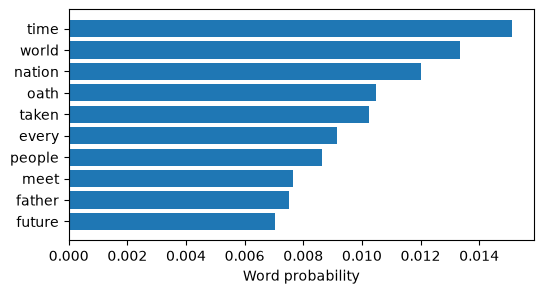

In [20]:
topic_id = 2

# Get words for topic
words = lda.show_topic(topic_id, topn=10)
words = np.array(words)
labels = words[:, 0]
weights = words[:, 1].astype(float) # Important!

fig, ax = plt.subplots(1, figsize=(6, 3)) 
ax.barh(labels[::-1], weights[::-1]) # [::-1] = Reverse list order
ax.set_xlabel('Word probability') 

## Create new database

In [22]:
#create new variable with the five first and five last speeches in the dataset

ten_speeches_obama = pd.concat([df.iloc[:5], df.iloc[-5:]]).reset_index(drop=True)

ten_speeches_obama.to_csv(data_dir / 'ten_speeches_obama.csv', index=False, encoding='utf-8')

print(len(ten_speeches_obama))
display(ten_speeches_obama.head())

10


,transcript,title,date,link,type,audience,topics,location
0,My fellow citizens: I stand here today humbled...,President Barack Obama's Inaugural Address,2009-01-21,https://obamawhitehouse.archives.gov/the-press...,address,general,political; representation,United States
1,"Hello, everybody. Please be seated. Still gett...",Remarks of the President in Welcoming Senior S...,2009-01-21,https://obamawhitehouse.archives.gov/the-press...,remarks,general,political; representation,United States
2,THE PRESIDENT: For the senior staff.\n\n\n\nTH...,Remarks of the President in Welcoming Senior S...,2009-01-21,https://obamawhitehouse.archives.gov/the-press...,remarks,general,political; representation,United States
3,"Well, it is great to see you. We are here toge...",Remarks by the President Before the Bipartisan...,2009-01-23,https://obamawhitehouse.archives.gov/the-press...,statement,general,political,United States
4,We begin this year and this Administration in ...,WEEKLY ADDRESS: President Barack Obama Discuss...,2009-01-24,https://obamawhitehouse.archives.gov/the-press...,address,general,political,United States
